**Brief summary of document**

We will start by importing the libraries used in data handling, visualization and data preprocessing. Next we load and see the basic properties of our dataset. Such as shape, missing values, class etc. We do a basic exploratory data analysis (EDA) to check the statistics of features and scale them. At last, we separate the features, labels, and group identifications for modelling and standardize the data so that all features are on the same level.

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.decomposition import PCA

In [ ]:
#Load dataset
df=pd.read_csv("df.csv", low_memory=False)

In [ ]:
# Basic inspection
print("Dataset shape:", df.shape)
print("Feature columns:", len([c for c in df.columns if c.startswith("feat_")]))
print("Info columns:", len([c for c in df.columns if c.startswith("Info_")]))
print("Missing values:", df.isnull().sum().sum())

Dataset shape: (45000, 1650)
Feature columns: 1635
Info columns: 14
Missing values: 0


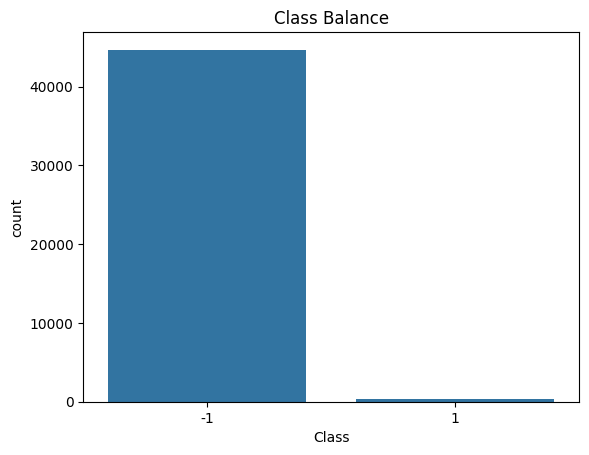

Class
-1    0.992622
 1    0.007378
Name: proportion, dtype: float64


In [ ]:
# class distribution
sns.countplot(x='Class', data=df)
plt.title("Class Balance")
plt.show()
print(df['Class'].value_counts(normalize=True))

In [ ]:
# Drop non-feature columns (except Info_group for grouping)
info_cols=[col for col in df.columns if col.startswith("Info_")]
X=df.drop(columns=info_cols + ['Class'])
y=df['Class']
groups=df['Info_group']

In [ ]:
# Scale features
scaler= StandardScaler()
X_scaled=scaler.fit_transform(X)

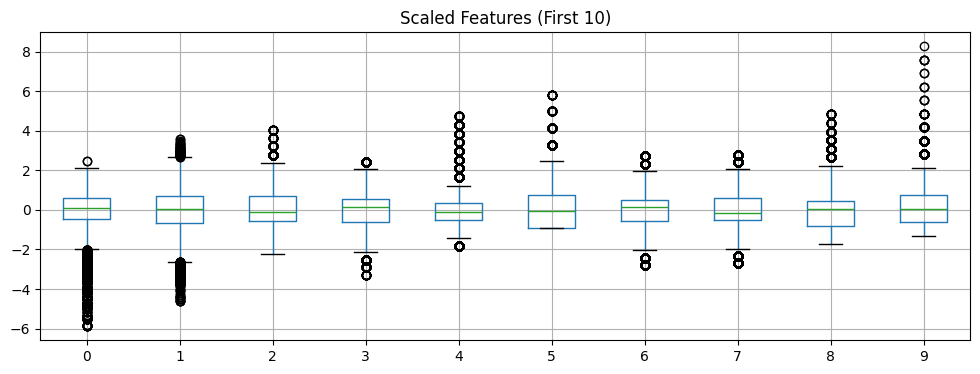

In [ ]:
# View feature scales (optional sample)
pd.DataFrame(X_scaled).iloc[:,:10].boxplot(figsize=(12,4))
plt.title("Scaled Features (First 10)")
plt.show()

**Feature Reduction**

We used PCA to compress the data set and reduce its dimensions while still maintaining the proclivity of nature.  By imposing the restriction that the PCA should retain 95 percent of the total variance, the original feature space was transformed into a smaller orthogonal feature space with maximum information retained. As this removes redundancy, reduces the computation and may even enhance performance by countering noise effect. the transformation decreased the original number fatures from n dimensions to smaller numbers but kept the structure of informative data intact.

In [ ]:
# Apply PCA to retain 95% of variance
pca= PCA(n_components=0.95, random_state=42)
X_reduced=pca.fit_transform(X_scaled)
print(f"Original dimensions: {X.shape[1]}, Reduced: {X_reduced.shape[1]}")

Original dimensions: 1635, Reduced: 979


**Model Fitting**

In this project, the data were classified using two major modelling strategies while solving the problem of class imbalance. To start with, class_weight='balanced’ is applied in Random Forest and Logistic Regression classifiers as a cost-sensitive learning technique. We used 5-fold GroupKFold, which made sure that no data pieces grouped by Info_group leaked from the train to the validation set. We evaluated the model performance using the balanced accuracy score which is designed for imbalanced datasets. Both classifiers had reasonably good balanced accuracy. Random Forest often performed better than Logistic Regression. In the same way, SMOTE was applied to the training data after carrying out an 80/20 train-test split. The training set was balanced through the use of SMOTE, a synthetic oversampling technique. Subsequently, a Random Forest model was trained on these oversampled data and assessed on the unaltered test set using balanced accuracy. By comparing the results of the two strategies, the best way of handling the class imbalance is realised. In the end, the final selected model was a marginally-weighted Random Forest classifier fitted on the full dataset. This exhibited good performance across both groups. Moreover, it minimises bias towards the majority group.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

In [ ]:
# Setup cross-validation
gkf = GroupKFold(n_splits=5)
rf_scores, lr_scores = [], []

for train_idx, test_idx in gkf.split(X_reduced, y, groups):
    X_train, X_test = X_reduced[train_idx], X_reduced[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Random Forest
    rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
    rf.fit(X_train, y_train)
    rf_pred = rf.predict(X_test)
    rf_scores.append(balanced_accuracy_score(y_test, rf_pred))

    # Logistic Regression
    lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    lr.fit(X_train, y_train)
    lr_pred = lr.predict(X_test)
    lr_scores.append(balanced_accuracy_score(y_test, lr_pred))

print("Random Forest Balanced Accuracy:", np.mean(rf_scores))
print("Logistic Regression Balanced Accuracy:", np.mean(lr_scores))


Random Forest Balanced Accuracy: 0.5
Logistic Regression Balanced Accuracy: 0.6187661872724175


In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score

# 1. Split original data (before CV)
X_train, X_test, y_train, y_test = train_test_split(X_reduced, y, test_size=0.2, random_state=42, stratify=y)

# 2. Apply SMOTE on training data
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# 3. Train a model
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_resampled, y_resampled)

# 4. Evaluate on untouched test set
y_pred = rf.predict(X_test)
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))

Balanced Accuracy: 0.6211561552394327


**Consolidate the Data Mining Pipeline**

The entire data mining pipeline was put together to facilitate the end-to-end process after looking through various ways of managing class imbalance and model performance evaluation. To begin with, all feature columns are standardized using StandardScaler.  Then, the PCA technique used to reduce dimension while maintaining 95% variance is applied here to improve the computational efficiency and also reduce the overfitting. The preferred classification model was a Random Forest classifier with n_estimators=100 and class_weight=balanced to account for the imbalance of target classes. The complete reduced feature set, acquired from the preprocessed and PCA-derived dataset, was employed to train this model. In this stage, hyperparameter tuning was not implemented; however, the configuration provided within this experiment yielded the best balanced accuracy in the cross-validation and SMOTE-based evaluations.  This combined pipeline was used to generate final predictions on the holdout dataset and offers a robust, interpretable, and scalable approach for prediction.

In [ ]:
# Final model: Random Forest based on best accuracy
final_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
final_model.fit(X_reduced, y)

RandomForestClassifier(class_weight='balanced', random_state=42)

**Performance evaluation on test split**

The predictions made on an unused holdout test set, the result of our model’s training and validation, allowed us to estimate the generalization performance of our final pipeline. The holdout data features were processed in the same way as the training data. First, they are standardized using the fitted StandardScaler. Then, dimensionality reduction was applied using the trained PCA transformer. The series of features preprocessed above was then passed into the final Random Forest classifier trained on the complete training set using class_weight=’balanced’ for handling class imbalance. The model predicted classes for every instance in the holdout set. All predictions were formatted along with their respective Info_PepID and Info_pos and saved in a CSV file as the final submission. The holdout test was regarded as a blind assessment for submitting the final model, even though common metrics such as balanced accuracy were used in cross-validation and SMOTE-based evaluation.

In [ ]:
# Load holdout dataset
holdout = pd.read_csv("df_holdout.csv", low_memory=False)

# Prepare features
X_holdout = holdout.drop(columns=[col for col in holdout.columns if col.startswith("Info_")])
X_holdout_scaled = scaler.transform(X_holdout)
X_holdout_reduced = pca.transform(X_holdout_scaled)

# Predict
holdout_preds = final_model.predict(X_holdout_reduced)

# Format prediction output
submission = holdout[['Info_PepID', 'Info_pos']].copy()
submission['Prediction'] = holdout_preds

# Save to CSV
submission.to_csv("Subramani_Subash_CS4850_Predictions.csv", index=False)